In [2]:
from pathlib import Path
import os
import random

import numpy as np
import matplotlib.pyplot as plt

import SimpleITK as sitk

from tqdm.auto import tqdm

In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PROCESSED_DATA_DIR = PROJECT_ROOT / "processed"

TRAIN_DIR = PROCESSED_DATA_DIR / "train"
VAL_DIR = PROCESSED_DATA_DIR / "val"
TEST_DIR = PROCESSED_DATA_DIR / "test"

print("Project:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_DIR)
print("Processed data:", PROCESSED_DATA_DIR)

Project: C:\Users\FAST\CHAOS_Preprocessing
Raw data: C:\Users\FAST\CHAOS_Preprocessing\data\raw
Processed data: C:\Users\FAST\CHAOS_Preprocessing\processed


In [10]:
train_dir = RAW_DATA_DIR / "CHAOS_Train_Sets"
test_dir = RAW_DATA_DIR / "CHAOS_Test_Sets"

print("TRAIN:")
for path in train_dir.rglob("*"):
    print(path)

print("\nTEST:")
for path in test_dir.rglob("*"):
    print(path)

TRAIN:
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\definitions.txt
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\MR
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\NOTES_PLEASE_READ.txt
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\1
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\10
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\14
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\16
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\18
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\19
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT\2
C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Se

In [11]:
# Define the actual dataset directories

CHAOS_TRAIN = RAW_DATA_DIR / "CHAOS_Train_Sets" / "Train_Sets"

CT_DIR = CHAOS_TRAIN / "CT"
MR_DIR = CHAOS_TRAIN / "MR"

print("CT directory:", CT_DIR)
print("MR directory:", MR_DIR)

print("\nCT patients:")
print(sorted([p.name for p in CT_DIR.iterdir() if p.is_dir()]))

print("\nMR patients:")
print(sorted([p.name for p in MR_DIR.iterdir() if p.is_dir()]))

CT directory: C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\CT
MR directory: C:\Users\FAST\CHAOS_Preprocessing\data\raw\CHAOS_Train_Sets\Train_Sets\MR

CT patients:
['1', '10', '14', '16', '18', '19', '2', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '5', '6', '8']

MR patients:
['1', '10', '13', '15', '19', '2', '20', '21', '22', '3', '31', '32', '33', '34', '36', '37', '38', '39', '5', '8']


In [12]:
# Inspect the structure of CT patient 1

ct_patient = CT_DIR / "1"

print("CT Patient 1:")
for path in ct_patient.iterdir():
    print(" ", path.name)

# Inspect the structure of MR patient 1

mr_patient = MR_DIR / "1"

print("\nMR Patient 1:")
for path in mr_patient.iterdir():
    print(" ", path.name)

CT Patient 1:
  DICOM_anon
  Ground

MR Patient 1:
  T1DUAL
  T2SPIR


In [13]:
# Detailed inspection of Patient 1

print("=" * 60)
print("CT Patient 1")
print("=" * 60)

for path in (CT_DIR / "1").rglob("*"):
    print(path.relative_to(CT_DIR / "1"))


print("\n" + "=" * 60)
print("MR Patient 1")
print("=" * 60)

for path in (MR_DIR / "1").rglob("*"):
    print(path.relative_to(MR_DIR / "1"))

CT Patient 1
DICOM_anon
Ground
DICOM_anon\i0000,0000b.dcm
DICOM_anon\i0001,0000b.dcm
DICOM_anon\i0002,0000b.dcm
DICOM_anon\i0003,0000b.dcm
DICOM_anon\i0004,0000b.dcm
DICOM_anon\i0005,0000b.dcm
DICOM_anon\i0006,0000b.dcm
DICOM_anon\i0007,0000b.dcm
DICOM_anon\i0008,0000b.dcm
DICOM_anon\i0009,0000b.dcm
DICOM_anon\i0010,0000b.dcm
DICOM_anon\i0011,0000b.dcm
DICOM_anon\i0012,0000b.dcm
DICOM_anon\i0013,0000b.dcm
DICOM_anon\i0014,0000b.dcm
DICOM_anon\i0015,0000b.dcm
DICOM_anon\i0016,0000b.dcm
DICOM_anon\i0017,0000b.dcm
DICOM_anon\i0018,0000b.dcm
DICOM_anon\i0019,0000b.dcm
DICOM_anon\i0020,0000b.dcm
DICOM_anon\i0021,0000b.dcm
DICOM_anon\i0022,0000b.dcm
DICOM_anon\i0023,0000b.dcm
DICOM_anon\i0024,0000b.dcm
DICOM_anon\i0025,0000b.dcm
DICOM_anon\i0026,0000b.dcm
DICOM_anon\i0027,0000b.dcm
DICOM_anon\i0028,0000b.dcm
DICOM_anon\i0029,0000b.dcm
DICOM_anon\i0030,0000b.dcm
DICOM_anon\i0031,0000b.dcm
DICOM_anon\i0032,0000b.dcm
DICOM_anon\i0033,0000b.dcm
DICOM_anon\i0034,0000b.dcm
DICOM_anon\i0035,0000b.d

In [14]:
# Load CT Patient 1 as a 3D volume

ct_patient_dir = CT_DIR / "1"
ct_dicom_dir = ct_patient_dir / "DICOM_anon"

reader = sitk.ImageSeriesReader()

ct_series_ids = reader.GetGDCMSeriesIDs(str(ct_dicom_dir))

print("CT Series IDs:")
print(ct_series_ids)

if not ct_series_ids:
    raise RuntimeError("No CT DICOM series found!")

ct_file_names = reader.GetGDCMSeriesFileNames(
    str(ct_dicom_dir),
    ct_series_ids[0]
)

reader.SetFileNames(ct_file_names)

ct_image = reader.Execute()
ct_array = sitk.GetArrayFromImage(ct_image)

print("\nCT volume information")
print("---------------------")
print("Array shape [Z, Y, X]:", ct_array.shape)
print("SimpleITK size [X, Y, Z]:", ct_image.GetSize())
print("Spacing [X, Y, Z]:", ct_image.GetSpacing())
print("Origin:", ct_image.GetOrigin())
print("Direction:", ct_image.GetDirection())
print("Data type:", ct_array.dtype)
print("Minimum:", ct_array.min())
print("Maximum:", ct_array.max())

CT Series IDs:
('1.3.46.670589.10.1.1.2163374719.1137684481.588647',)

CT volume information
---------------------
Array shape [Z, Y, X]: (96, 512, 512)
SimpleITK size [X, Y, Z]: (512, 512, 96)
Spacing [X, Y, Z]: (0.687671, 0.687671, 1.5)
Origin: (-167.7859, -176.0438, -226.5)
Direction: (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)
Data type: int32
Minimum: -1200
Maximum: 1264


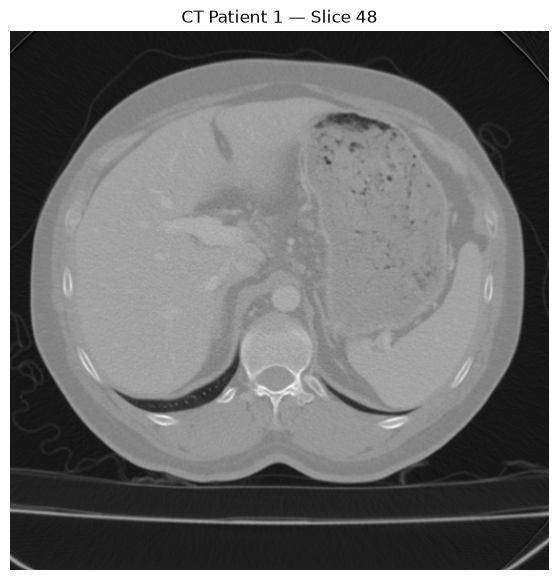

In [15]:
# Visualize the middle CT slice

mid_slice = ct_array.shape[0] // 2

plt.figure(figsize=(7, 7))
plt.imshow(ct_array[mid_slice], cmap="gray")
plt.title(f"CT Patient 1 — Slice {mid_slice}")
plt.axis("off")
plt.show()

In [16]:
# Check CT masks for Patient 1

mask_dir = ct_patient_dir / "Ground"

mask_files = sorted(mask_dir.glob("*.png"))

print("Number of CT mask files:", len(mask_files))
print("\nFirst 5 masks:")
for f in mask_files[:5]:
    print(f.name)

print("\nLast 5 masks:")
for f in mask_files[-5:]:
    print(f.name)

Number of CT mask files: 96

First 5 masks:
liver_GT_000.png
liver_GT_001.png
liver_GT_002.png
liver_GT_003.png
liver_GT_004.png

Last 5 masks:
liver_GT_091.png
liver_GT_092.png
liver_GT_093.png
liver_GT_094.png
liver_GT_095.png


In [17]:
from PIL import Image
import numpy as np

mask = np.array(Image.open(mask_files[mid_slice]))

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask minimum:", mask.min())
print("Mask maximum:", mask.max())
print("Unique values:", np.unique(mask))

Mask shape: (512, 512)
Mask dtype: bool
Mask minimum: False
Mask maximum: True
Unique values: [False  True]


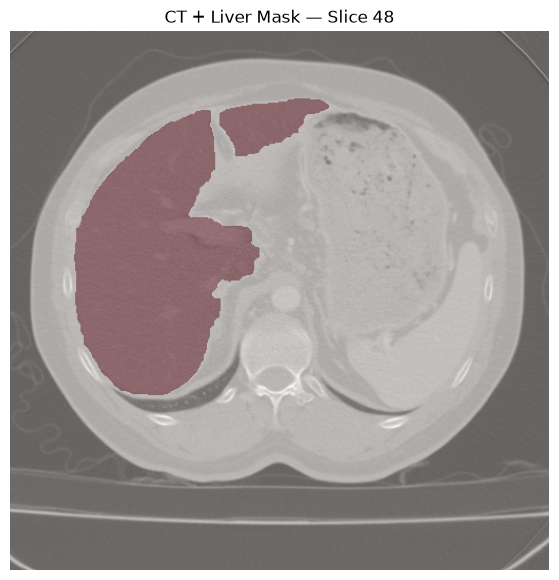

In [18]:
plt.figure(figsize=(7, 7))

plt.imshow(ct_array[mid_slice], cmap="gray")
plt.imshow(mask, cmap="Reds", alpha=0.35)

plt.title(f"CT + Liver Mask — Slice {mid_slice}")
plt.axis("off")
plt.show()

In [20]:
from pathlib import Path
import json
import re
import random
import platform
import sys
import os

import numpy as np
import pandas as pd
import SimpleITK as sitk
from PIL import Image
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("SimpleITK:", sitk.Version_VersionString())
print("NumPy:", np.__version__)

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
SimpleITK: 2.5.6
NumPy: 2.3.5


In [21]:
# ============================================================
# CONFIGURATION
# ============================================================

RANDOM_SEED = 42

# Change this path if necessary
RAW_ROOT = Path("data/raw")

TRAIN_ROOT = RAW_ROOT / "CHAOS_Train_Sets" / "Train_Sets"
OFFICIAL_TEST_ROOT = RAW_ROOT / "CHAOS_Test_Sets" / "Test_Sets"

OUTPUT_ROOT = Path("preprocessed")

TARGET_SPACING = (1.5, 1.5, 1.5)

# CT
CT_WINDOW_MIN = -200.0
CT_WINDOW_MAX = 250.0

# MRI
MRI_N4 = True
MRI_ZSCORE = True

# T2 -> T1
REGISTER_T2_TO_T1 = True

# Slice selection
# Training: foreground-only
# Validation/Test: all slices
SLICE_POLICY = "foreground_train_all_eval"

# Registration parameters
REGISTRATION_SEED = 42

print("RAW_ROOT:", RAW_ROOT.resolve())
print("OUTPUT_ROOT:", OUTPUT_ROOT.resolve())

RAW_ROOT: C:\Users\FAST\CHAOS_Preprocessing\data\raw
OUTPUT_ROOT: C:\Users\FAST\CHAOS_Preprocessing\preprocessed


In [22]:
# ============================================================
# DATASET STRUCTURE CHECK
# ============================================================

required_paths = [
    TRAIN_ROOT,
    TRAIN_ROOT / "CT",
    TRAIN_ROOT / "MR",
    OFFICIAL_TEST_ROOT,
    OFFICIAL_TEST_ROOT / "CT",
    OFFICIAL_TEST_ROOT / "MR",
]

for path in required_paths:
    print(f"{'OK':<5} {path}" if path.exists() else f"{'MISSING':<5} {path}")

if not TRAIN_ROOT.exists():
    raise FileNotFoundError(
        f"Training dataset not found:\n{TRAIN_ROOT.resolve()}"
    )

if not (TRAIN_ROOT / "CT").exists():
    raise FileNotFoundError("CT directory missing.")

if not (TRAIN_ROOT / "MR").exists():
    raise FileNotFoundError("MR directory missing.")

OK    data\raw\CHAOS_Train_Sets\Train_Sets
OK    data\raw\CHAOS_Train_Sets\Train_Sets\CT
OK    data\raw\CHAOS_Train_Sets\Train_Sets\MR
OK    data\raw\CHAOS_Test_Sets\Test_Sets
OK    data\raw\CHAOS_Test_Sets\Test_Sets\CT
OK    data\raw\CHAOS_Test_Sets\Test_Sets\MR


In [23]:
# ============================================================
# DATASET DISCOVERY
# ============================================================

def numeric_case_ids(root):
    ids = []

    if not root.exists():
        return ids

    for p in root.iterdir():
        if p.is_dir() and p.name.isdigit():
            ids.append(int(p.name))

    return sorted(ids)


ct_train_ids = numeric_case_ids(TRAIN_ROOT / "CT")
mr_train_ids = numeric_case_ids(TRAIN_ROOT / "MR")

ct_test_ids = numeric_case_ids(OFFICIAL_TEST_ROOT / "CT")
mr_test_ids = numeric_case_ids(OFFICIAL_TEST_ROOT / "MR")

print("CT labeled:", ct_train_ids)
print("MR labeled:", mr_train_ids)

print()
print("CT official test:", ct_test_ids)
print("MR official test:", mr_test_ids)

assert len(ct_train_ids) == 20, f"Expected 20 labeled CT cases, got {len(ct_train_ids)}"
assert len(mr_train_ids) == 20, f"Expected 20 labeled MR cases, got {len(mr_train_ids)}"

assert len(ct_test_ids) == 20, f"Expected 20 CT test cases, got {len(ct_test_ids)}"
assert len(mr_test_ids) == 20, f"Expected 20 MR test cases, got {len(mr_test_ids)}"

CT labeled: [1, 2, 5, 6, 8, 10, 14, 16, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
MR labeled: [1, 2, 3, 5, 8, 10, 13, 15, 19, 20, 21, 22, 31, 32, 33, 34, 36, 37, 38, 39]

CT official test: [3, 4, 7, 9, 11, 12, 13, 15, 17, 20, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
MR official test: [4, 6, 7, 9, 11, 12, 14, 16, 17, 18, 23, 24, 25, 26, 27, 28, 29, 30, 35, 40]


In [24]:
# ============================================================
# OFFICIAL CHAOS ID VERIFICATION
# ============================================================

EXPECTED_CT_TRAIN = [
    1, 2, 5, 6, 8, 10, 14, 16, 18, 19,
    21, 22, 23, 24, 25, 26, 27, 28, 29, 30
]

EXPECTED_CT_TEST = [
    3, 4, 7, 9, 11, 12, 13, 15, 17, 20,
    31, 32, 33, 34, 35, 36, 37, 38, 39, 40
]

EXPECTED_MR_TRAIN = [
    1, 2, 3, 5, 8, 10, 13, 15, 19, 20,
    21, 22, 31, 32, 33, 34, 36, 37, 38, 39
]

EXPECTED_MR_TEST = [
    4, 6, 7, 9, 11, 12, 14, 16, 17, 18,
    23, 24, 25, 26, 27, 28, 29, 30, 35, 40
]

assert ct_train_ids == EXPECTED_CT_TRAIN
assert ct_test_ids == EXPECTED_CT_TEST
assert mr_train_ids == EXPECTED_MR_TRAIN
assert mr_test_ids == EXPECTED_MR_TEST

print("✓ Official CT IDs verified")
print("✓ Official MR IDs verified")
print("✓ CT/MR IDs are treated independently")

✓ Official CT IDs verified
✓ Official MR IDs verified
✓ CT/MR IDs are treated independently


In [26]:
# ============================================================
# PATIENT-LEVEL SPLITS
# ============================================================

def create_split(ids, seed=42):
    ids = sorted(ids)

    shuffled = ids.copy()

    rng = random.Random(seed)
    rng.shuffle(shuffled)

    test = shuffled[:4]
    val = shuffled[4:6]
    train = shuffled[6:]

    return {
        "train": sorted(train),
        "val": sorted(val),
        "test": sorted(test),
    }


ct_splits = create_split(ct_train_ids, RANDOM_SEED)
mr_splits = create_split(mr_train_ids, RANDOM_SEED)

print("CT splits")
print("Train:", ct_splits["train"])
print("Val:  ", ct_splits["val"])
print("Test: ", ct_splits["test"])

print()
print("MR splits")
print("Train:", mr_splits["train"])
print("Val:  ", mr_splits["val"])
print("Test: ", mr_splits["test"])

CT splits
Train: [1, 2, 5, 6, 14, 16, 18, 21, 22, 23, 26, 27, 28, 29]
Val:   [19, 24]
Test:  [8, 10, 25, 30]

MR splits
Train: [1, 2, 3, 5, 13, 15, 19, 21, 22, 31, 34, 36, 37, 38]
Val:   [20, 32]
Test:  [8, 10, 33, 39]


In [27]:
# ============================================================
# SAVE SPLITS
# ============================================================

def save_splits(splits, modality):
    split_dir = OUTPUT_ROOT / "splits" / modality
    split_dir.mkdir(parents=True, exist_ok=True)

    for split_name, ids in splits.items():
        path = split_dir / f"{split_name}_patients.txt"

        with open(path, "w") as f:
            for case_id in ids:
                f.write(f"{case_id}\n")

        print("Saved:", path)


save_splits(ct_splits, "ct")
save_splits(mr_splits, "mr")

Saved: preprocessed\splits\ct\train_patients.txt
Saved: preprocessed\splits\ct\val_patients.txt
Saved: preprocessed\splits\ct\test_patients.txt
Saved: preprocessed\splits\mr\train_patients.txt
Saved: preprocessed\splits\mr\val_patients.txt
Saved: preprocessed\splits\mr\test_patients.txt


In [28]:
# ============================================================
# SAVE CONFIGURATION
# ============================================================

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

config = {
    "random_seed": RANDOM_SEED,
    "target_spacing": TARGET_SPACING,
    "ct_window": [
        CT_WINDOW_MIN,
        CT_WINDOW_MAX
    ],
    "mri_n4": MRI_N4,
    "mri_zscore": MRI_ZSCORE,
    "register_t2_to_t1": REGISTER_T2_TO_T1,
    "slice_policy": SLICE_POLICY,
    "ct_mr_paired": False,
    "ct_classes": {
        "0": "background",
        "1": "liver"
    },
    "mr_classes": {
        "0": "background",
        "1": "liver",
        "2": "right_kidney",
        "3": "left_kidney",
        "4": "spleen"
    },
    "software": {
        "python": sys.version,
        "simpleitk": sitk.Version_VersionString(),
        "numpy": np.__version__,
        "platform": platform.platform()
    }
}

with open(OUTPUT_ROOT / "config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Saved:", OUTPUT_ROOT / "config.json")

Saved: preprocessed\config.json


In [30]:
# ============================================================
# DICOM UTILITIES
# ============================================================

def read_dicom_header(filename):
    """
    Read DICOM metadata without loading the complete pixel volume.
    """
    reader = sitk.ImageFileReader()
    reader.SetFileName(str(filename))
    reader.LoadPrivateTagsOn()
    reader.ReadImageInformation()

    metadata = {}

    for key in [
        "0008|0060",  # Modality
        "0020|000e",  # SeriesInstanceUID
        "0020|0013",  # InstanceNumber
        "0020|0032",  # ImagePositionPatient
        "0020|0037",  # ImageOrientationPatient
        "0018|0050",  # SliceThickness
        "0018|0088",  # SpacingBetweenSlices
        "0028|1052",  # RescaleIntercept
        "0028|1053",  # RescaleSlope
        "0028|0103",  # PixelRepresentation
    ]:
        if reader.HasMetaDataKey(key):
            metadata[key] = reader.GetMetaData(key)

    return metadata


def parse_float_list(value):
    if value is None:
        return None

    try:
        return [float(x) for x in value.split("\\")]
    except Exception:
        return None


def parse_float(value, default=None):
    try:
        return float(value)
    except Exception:
        return default


def get_series_files(dicom_dir):
    dicom_dir = Path(dicom_dir)

    series_ids = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_dir))

    if not series_ids:
        raise RuntimeError(f"No DICOM series found in {dicom_dir}")

    if len(series_ids) > 1:
        print(f"WARNING: {dicom_dir} contains {len(series_ids)} series")

        for uid in series_ids:
            files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
                str(dicom_dir), uid
            )
            print("  UID:", uid, "files:", len(files))

        # For this dataset a case directory should represent one series.
        raise RuntimeError(
            f"Multiple DICOM series found in {dicom_dir}. "
            "Refusing to silently choose one."
        )

    series_uid = series_ids[0]

    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(
        str(dicom_dir),
        series_uid
    )

    return list(files), series_uid


def load_dicom_series(dicom_dir):
    files, series_uid = get_series_files(dicom_dir)

    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    reader.MetaDataDictionaryArrayUpdateOn()
    reader.LoadPrivateTagsOn()

    image = reader.Execute()

    return image, files, series_uid

In [31]:
# ============================================================
# DICOM GEOMETRY AUDIT
# ============================================================

def audit_dicom_series(files, image, series_uid):
    headers = [read_dicom_header(f) for f in files]

    positions = []
    orientations = []

    for h in headers:
        ipp = parse_float_list(h.get("0020|0032"))
        iop = parse_float_list(h.get("0020|0037"))

        positions.append(ipp)
        orientations.append(iop)

    valid_positions = [
        p for p in positions
        if p is not None and len(p) == 3
    ]

    valid_orientations = [
        o for o in orientations
        if o is not None and len(o) == 6
    ]

    result = {
        "series_uid": series_uid,
        "file_count": len(files),
        "size_xyz": list(image.GetSize()),
        "array_shape_zyx": list(sitk.GetArrayFromImage(image).shape),
        "spacing_xyz": list(image.GetSpacing()),
        "origin_xyz": list(image.GetOrigin()),
        "direction": list(image.GetDirection()),
        "pixel_type": image.GetPixelIDTypeAsString(),
        "positions_available": len(valid_positions) == len(files),
        "orientations_available": len(valid_orientations) == len(files),
    }

    # --------------------------------------------------------
    # Orientation
    # --------------------------------------------------------

    if valid_orientations:
        first_iop = valid_orientations[0]

        result["image_orientation_patient"] = first_iop

        if all(
            np.allclose(o, first_iop, atol=1e-5)
            for o in valid_orientations
        ):
            result["orientation_consistent"] = True
        else:
            result["orientation_consistent"] = False

        row = np.array(first_iop[:3])
        col = np.array(first_iop[3:])
        normal = np.cross(row, col)

        result["slice_normal"] = normal.tolist()

        if valid_positions:
            projections = [
                float(np.dot(np.array(p), normal))
                for p in valid_positions
            ]

            diffs = np.diff(projections)

            result["position_projection_min"] = float(min(projections))
            result["position_projection_max"] = float(max(projections))
            result["position_step_median"] = (
                float(np.median(np.abs(diffs)))
                if len(diffs)
                else None
            )
            result["position_step_min"] = (
                float(np.min(np.abs(diffs)))
                if len(diffs)
                else None
            )
            result["position_step_max"] = (
                float(np.max(np.abs(diffs)))
                if len(diffs)
                else None
            )

            result["position_monotonic"] = bool(
                np.all(diffs > 0) or np.all(diffs < 0)
            )

    # --------------------------------------------------------
    # CT rescale information
    # --------------------------------------------------------

    slopes = []
    intercepts = []
    pixel_representations = []

    for h in headers:
        if "0028|1053" in h:
            slopes.append(parse_float(h["0028|1053"]))

        if "0028|1052" in h:
            intercepts.append(parse_float(h["0028|1052"]))

        if "0028|0103" in h:
            pixel_representations.append(h["0028|0103"])

    result["rescale_slopes"] = sorted(set(x for x in slopes if x is not None))
    result["rescale_intercepts"] = sorted(
        set(x for x in intercepts if x is not None)
    )
    result["pixel_representations"] = sorted(
        set(pixel_representations)
    )

    return result

In [32]:
# ============================================================
# CT PATIENT 1 AUDIT
# ============================================================

ct1_dir = TRAIN_ROOT / "CT" / "1" / "DICOM_anon"

ct1_image, ct1_files, ct1_uid = load_dicom_series(ct1_dir)

ct1_audit = audit_dicom_series(
    ct1_files,
    ct1_image,
    ct1_uid
)

print(json.dumps(ct1_audit, indent=4))

ct1_array = sitk.GetArrayFromImage(ct1_image)

print("\nArray shape:", ct1_array.shape)
print("Min:", ct1_array.min())
print("Max:", ct1_array.max())
print("Mean:", ct1_array.mean())

{
    "series_uid": "1.3.46.670589.10.1.1.2163374719.1137684481.588647",
    "file_count": 96,
    "size_xyz": [
        512,
        512,
        96
    ],
    "array_shape_zyx": [
        96,
        512,
        512
    ],
    "spacing_xyz": [
        0.687671,
        0.687671,
        1.5
    ],
    "origin_xyz": [
        -167.7859,
        -176.0438,
        -226.5
    ],
    "direction": [
        1.0,
        0.0,
        0.0,
        0.0,
        1.0,
        0.0,
        0.0,
        0.0,
        1.0
    ],
    "pixel_type": "32-bit signed integer",
    "positions_available": true,
    "orientations_available": true,
    "image_orientation_patient": [
        1.0,
        0.0,
        0.0,
        0.0,
        1.0,
        0.0
    ],
    "orientation_consistent": true,
    "slice_normal": [
        0.0,
        0.0,
        1.0
    ],
    "position_projection_min": -226.5,
    "position_projection_max": -84.0,
    "position_step_median": 1.5,
    "position_step_min": 1.5,
  

In [33]:
# ============================================================
# CT LABEL ORDER VALIDATION
# ============================================================

def last_integer_from_filename(path):
    numbers = re.findall(r"\d+", Path(path).stem)

    if not numbers:
        return None

    return int(numbers[-1])


def load_ct_masks(case_dir, dicom_files):
    ground_dir = Path(case_dir) / "Ground"

    mask_files = sorted(
        ground_dir.glob("*.png"),
        key=lambda p: last_integer_from_filename(p)
    )

    if len(mask_files) != len(dicom_files):
        raise ValueError(
            f"CT label count mismatch:\n"
            f"DICOM = {len(dicom_files)}\n"
            f"PNG = {len(mask_files)}"
        )

    mask_indices = [
        last_integer_from_filename(p)
        for p in mask_files
    ]

    expected = list(range(len(mask_files)))

    if mask_indices != expected:
        raise ValueError(
            f"CT mask indices are not contiguous 0..N-1.\n"
            f"Found: {mask_indices[:20]}..."
        )

    dicom_indices = [
        last_integer_from_filename(f)
        for f in dicom_files
    ]

    # Filename numbers should be monotonic in GDCM order.
    # We do NOT use the number as the spatial ordering itself.
    if all(x is not None for x in dicom_indices):
        diffs = np.diff(dicom_indices)

        if not (np.all(diffs > 0) or np.all(diffs < 0)):
            raise ValueError(
                "CT DICOM filename indices are not monotonic "
                "in GDCM series order. Refusing to guess PNG alignment."
            )

    masks = []

    for path in mask_files:
        arr = np.asarray(Image.open(path).convert("L"))

        # CT is explicitly binary.
        mask = (arr > 0).astype(np.uint8)

        masks.append(mask)

    mask_volume = np.stack(masks, axis=0)

    return mask_volume, mask_files

In [34]:
# ============================================================
# CT INTENSITY PREPROCESSING
# ============================================================

def percentile_stats(array):
    finite = array[np.isfinite(array)]

    return {
        "min": float(np.min(finite)),
        "max": float(np.max(finite)),
        "mean": float(np.mean(finite)),
        "p1": float(np.percentile(finite, 1)),
        "p99": float(np.percentile(finite, 99)),
    }


def preprocess_ct_intensity(image):
    arr = sitk.GetArrayFromImage(image).astype(np.float32)

    pre_stats = percentile_stats(arr)

    below = float(np.mean(arr < CT_WINDOW_MIN) * 100)
    above = float(np.mean(arr > CT_WINDOW_MAX) * 100)

    clipped = np.clip(
        arr,
        CT_WINDOW_MIN,
        CT_WINDOW_MAX
    )

    normalized = (
        clipped - CT_WINDOW_MIN
    ) / (
        CT_WINDOW_MAX - CT_WINDOW_MIN
    )

    normalized = normalized.astype(np.float32)

    result = sitk.GetImageFromArray(normalized)
    result.CopyInformation(image)

    stats = {
        "pre_clip": pre_stats,
        "percent_below_window": below,
        "percent_above_window": above,
        "window": [
            CT_WINDOW_MIN,
            CT_WINDOW_MAX
        ],
        "post_clip_min": float(clipped.min()),
        "post_clip_max": float(clipped.max()),
        "post_normalization_min": float(normalized.min()),
        "post_normalization_max": float(normalized.max()),
    }

    return result, stats

In [35]:
# ============================================================
# RESAMPLING
# ============================================================

def make_reference_grid(image, target_spacing=TARGET_SPACING):
    old_size = np.array(image.GetSize(), dtype=float)
    old_spacing = np.array(image.GetSpacing(), dtype=float)
    new_spacing = np.array(target_spacing, dtype=float)

    # Preserve physical extent from first voxel to last voxel.
    new_size = np.floor(
        ((old_size - 1) * old_spacing / new_spacing) + 0.5
    ).astype(int) + 1

    new_size = [
        max(1, int(x))
        for x in new_size
    ]

    reference = sitk.Image(
        new_size,
        image.GetPixelID()
    )

    reference.SetSpacing(tuple(target_spacing))
    reference.SetOrigin(image.GetOrigin())
    reference.SetDirection(image.GetDirection())

    return reference


def resample_image(
    image,
    reference,
    interpolator=sitk.sitkLinear,
    default_value=0.0
):
    return sitk.Resample(
        image,
        reference,
        sitk.Transform(),
        interpolator,
        default_value,
        image.GetPixelID()
    )


def resample_label(
    label,
    reference
):
    label = sitk.Cast(label, sitk.sitkUInt8)

    return sitk.Resample(
        label,
        reference,
        sitk.Transform(),
        sitk.sitkNearestNeighbor,
        0,
        sitk.sitkUInt8
    )

In [36]:
# ============================================================
# MRI LABEL PROCESSING
# ============================================================

MR_LABEL_RANGES = {
    1: (55, 70),    # liver
    2: (110, 135),  # right kidney
    3: (175, 200),  # left kidney
    4: (240, 255),  # spleen
}


def audit_mr_png_values(mask_files):
    all_values = set()

    per_file = {}

    for path in mask_files:
        arr = np.asarray(
            Image.open(path).convert("L"),
            dtype=np.uint8
        )

        values = np.unique(arr).tolist()

        per_file[path.name] = values
        all_values.update(values)

    all_values = sorted(all_values)

    unexpected = []

    for value in all_values:
        if value == 0:
            continue

        valid = any(
            low <= value <= high
            for low, high in MR_LABEL_RANGES.values()
        )

        if not valid:
            unexpected.append(value)

    if unexpected:
        raise ValueError(
            f"Unexpected MR label values found: {unexpected}"
        )

    return all_values, per_file


def convert_mr_mask(arr):
    """
    Convert CHAOS grayscale mask to:

    0 = background
    1 = liver
    2 = right kidney
    3 = left kidney
    4 = spleen
    """

    arr = np.asarray(arr, dtype=np.uint8)

    output = np.zeros_like(arr, dtype=np.uint8)

    for class_id, (low, high) in MR_LABEL_RANGES.items():
        output[
            (arr >= low) &
            (arr <= high)
        ] = class_id

    return output

In [37]:
# ============================================================
# MRI LABEL/DICOM CORRESPONDENCE
# ============================================================

def load_mr_masks_by_stem(dicom_files, ground_dir):
    ground_dir = Path(ground_dir)

    png_by_stem = {
        p.stem: p
        for p in ground_dir.glob("*.png")
    }

    missing = []

    mask_files = []

    for dcm in dicom_files:
        stem = Path(dcm).stem

        if stem not in png_by_stem:
            missing.append(stem)
        else:
            mask_files.append(png_by_stem[stem])

    if missing:
        raise ValueError(
            f"Missing MR GT for DICOM stems: {missing[:10]}"
        )

    if len(mask_files) != len(dicom_files):
        raise ValueError(
            "MR DICOM/GT count mismatch."
        )

    unique_values, per_file = audit_mr_png_values(mask_files)

    masks = []

    for path in mask_files:
        raw = np.asarray(
            Image.open(path).convert("L"),
            dtype=np.uint8
        )

        masks.append(
            convert_mr_mask(raw)
        )

    volume = np.stack(masks, axis=0)

    return volume, mask_files, unique_values

In [38]:
# ============================================================
# MRI BODY MASK + N4
# ============================================================

def make_mri_body_mask(image):
    image = sitk.Cast(image, sitk.sitkFloat32)

    try:
        mask = sitk.OtsuThreshold(
            image,
            0,
            1
        )

        # Keep the largest connected component.
        cc = sitk.ConnectedComponent(mask)

        relabeled = sitk.RelabelComponent(
            cc,
            sortByObjectSize=True
        )

        mask = sitk.BinaryThreshold(
            relabeled,
            lowerThreshold=1,
            upperThreshold=1,
            insideValue=1,
            outsideValue=0
        )

        arr = sitk.GetArrayFromImage(mask)

        # If Otsu produces an unusably small mask,
        # fallback to positive voxels.
        if np.mean(arr > 0) < 0.01:
            mask = image > 0

    except Exception:
        mask = image > 0

    return sitk.Cast(mask, sitk.sitkUInt8)


def n4_correct(image, mask):
    image = sitk.Cast(image, sitk.sitkFloat32)
    mask = sitk.Cast(mask, sitk.sitkUInt8)

    arr = sitk.GetArrayFromImage(image)

    # N4 works more safely on non-negative intensities.
    shift = 0.0

    min_value = float(np.min(arr))

    if min_value < 0:
        shift = -min_value
        image_for_n4 = image + shift
    else:
        image_for_n4 = image

    corrected = sitk.N4BiasFieldCorrection(
        image_for_n4,
        mask
    )

    if shift != 0:
        corrected = corrected - shift

    return sitk.Cast(corrected, sitk.sitkFloat32), shift

In [39]:
# ============================================================
# MRI FOREGROUND Z-SCORE
# ============================================================

def foreground_zscore(image, mask):
    arr = sitk.GetArrayFromImage(image).astype(np.float32)
    mask_arr = sitk.GetArrayFromImage(mask) > 0

    foreground = arr[mask_arr]

    if foreground.size == 0:
        raise ValueError("MRI foreground mask is empty.")

    mu = float(np.mean(foreground))
    sigma = float(np.std(foreground))

    if sigma < 1e-8:
        normalized = np.zeros_like(arr, dtype=np.float32)
        normalized[mask_arr] = arr[mask_arr] - mu
    else:
        normalized = np.zeros_like(arr, dtype=np.float32)
        normalized[mask_arr] = (
            arr[mask_arr] - mu
        ) / sigma

    result = sitk.GetImageFromArray(normalized)
    result.CopyInformation(image)

    stats = {
        "foreground_voxels": int(foreground.size),
        "mean": mu,
        "std": sigma,
        "post_min": float(normalized[mask_arr].min()),
        "post_max": float(normalized[mask_arr].max()),
    }

    return result, stats

In [40]:
# ============================================================
# GEOMETRY COMPARISON
# ============================================================

def geometry_dict(image):
    return {
        "size": list(image.GetSize()),
        "spacing": list(image.GetSpacing()),
        "origin": list(image.GetOrigin()),
        "direction": list(image.GetDirection()),
    }


def geometry_equal(
    image_a,
    image_b,
    spacing_tol=1e-5,
    origin_tol=1e-3,
    direction_tol=1e-5
):
    if image_a.GetSize() != image_b.GetSize():
        return False

    if not np.allclose(
        image_a.GetSpacing(),
        image_b.GetSpacing(),
        atol=spacing_tol
    ):
        return False

    if not np.allclose(
        image_a.GetOrigin(),
        image_b.GetOrigin(),
        atol=origin_tol
    ):
        return False

    if not np.allclose(
        image_a.GetDirection(),
        image_b.GetDirection(),
        atol=direction_tol
    ):
        return False

    return True

In [41]:
# ============================================================
# T2 -> T1 REGISTRATION
# ============================================================

def register_t2_to_t1(fixed_t1, moving_t2):
    """
    Fixed  = T1 InPhase
    Moving = T2SPIR

    Rigid followed by affine.
    Metric = Mattes Mutual Information.
    """

    fixed = sitk.Cast(fixed_t1, sitk.sitkFloat32)
    moving = sitk.Cast(moving_t2, sitk.sitkFloat32)

    # --------------------------------------------------------
    # RIGID
    # --------------------------------------------------------

    initial_rigid = sitk.CenteredTransformInitializer(
        fixed,
        moving,
        sitk.Euler3DTransform(),
        sitk.CenteredTransformInitializerFilter.GEOMETRY
    )

    rigid_method = sitk.ImageRegistrationMethod()

    rigid_method.SetMetricAsMattesMutualInformation(
        numberOfHistogramBins=50
    )

    rigid_method.SetMetricSamplingStrategy(
        rigid_method.RANDOM
    )

    rigid_method.SetMetricSamplingPercentage(
        0.20,
        seed=REGISTRATION_SEED
    )

    rigid_method.SetInterpolator(
        sitk.sitkLinear
    )

    rigid_method.SetOptimizerAsRegularStepGradientDescent(
        learningRate=2.0,
        minStep=0.01,
        numberOfIterations=150,
        relaxationFactor=0.5
    )

    rigid_method.SetOptimizerScalesFromPhysicalShift()

    rigid_method.SetShrinkFactorsPerLevel(
        [4, 2, 1]
    )

    rigid_method.SetSmoothingSigmasPerLevel(
        [2, 1, 0]
    )

    rigid_method.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

    rigid_method.SetInitialTransform(
        initial_rigid,
        inPlace=False
    )

    rigid_transform = rigid_method.Execute(
        fixed,
        moving
    )

    print(
        "Rigid registration metric:",
        rigid_method.GetMetricValue()
    )

    # --------------------------------------------------------
    # AFFINE
    # --------------------------------------------------------

    affine = sitk.AffineTransform(3)

    affine.SetCenter(
        rigid_transform.GetCenter()
    )

    affine.SetMatrix(
        rigid_transform.GetMatrix()
    )

    affine.SetTranslation(
        rigid_transform.GetTranslation()
    )

    affine_method = sitk.ImageRegistrationMethod()

    affine_method.SetMetricAsMattesMutualInformation(
        numberOfHistogramBins=50
    )

    affine_method.SetMetricSamplingStrategy(
        affine_method.RANDOM
    )

    affine_method.SetMetricSamplingPercentage(
        0.20,
        seed=REGISTRATION_SEED
    )

    affine_method.SetInterpolator(
        sitk.sitkLinear
    )

    affine_method.SetOptimizerAsRegularStepGradientDescent(
        learningRate=1.0,
        minStep=0.005,
        numberOfIterations=200,
        relaxationFactor=0.5
    )

    affine_method.SetOptimizerScalesFromPhysicalShift()

    affine_method.SetShrinkFactorsPerLevel(
        [4, 2, 1]
    )

    affine_method.SetSmoothingSigmasPerLevel(
        [2, 1, 0]
    )

    affine_method.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

    affine_method.SetInitialTransform(
        affine,
        inPlace=False
    )

    final_transform = affine_method.Execute(
        fixed,
        moving
    )

    print(
        "Affine registration metric:",
        affine_method.GetMetricValue()
    )

    return final_transform

In [42]:
# ============================================================
# APPLY REGISTRATION
# ============================================================

def apply_transform_to_image(
    moving,
    fixed,
    transform
):
    return sitk.Resample(
        moving,
        fixed,
        transform,
        sitk.sitkLinear,
        0.0,
        sitk.sitkFloat32
    )


def apply_transform_to_label(
    moving_label,
    fixed,
    transform
):
    return sitk.Resample(
        moving_label,
        fixed,
        transform,
        sitk.sitkNearestNeighbor,
        0,
        sitk.sitkUInt8
    )

In [43]:
# ============================================================
# LABEL VALIDATION
# ============================================================

def validate_ct_label(label):
    arr = sitk.GetArrayFromImage(label)

    values = np.unique(arr)

    if not np.all(np.isin(values, [0, 1])):
        raise ValueError(
            f"Invalid CT labels: {values}"
        )

    return {
        "unique_values": values.tolist(),
        "voxel_counts": {
            str(int(v)): int(np.sum(arr == v))
            for v in values
        },
        "empty_slices": int(
            np.sum(
                np.sum(arr > 0, axis=(1, 2)) == 0
            )
        )
    }


def validate_mr_label(label):
    arr = sitk.GetArrayFromImage(label)

    values = np.unique(arr)

    if not np.all(
        np.isin(values, [0, 1, 2, 3, 4])
    ):
        raise ValueError(
            f"Invalid MR labels: {values}"
        )

    return {
        "unique_values": values.tolist(),
        "voxel_counts": {
            str(int(v)): int(np.sum(arr == v))
            for v in values
        },
        "empty_slices": int(
            np.sum(
                np.sum(arr > 0, axis=(1, 2)) == 0
            )
        )
    }

In [44]:
# ============================================================
# SLICE SELECTION
# ============================================================

def select_slices(
    label,
    split,
    policy=SLICE_POLICY
):
    arr = sitk.GetArrayFromImage(label)

    foreground_per_slice = np.sum(
        arr > 0,
        axis=(1, 2)
    )

    if policy == "foreground_train_all_eval":

        if split == "train":
            indices = np.where(
                foreground_per_slice > 0
            )[0]

        else:
            indices = np.arange(
                arr.shape[0]
            )

    elif policy == "all":
        indices = np.arange(arr.shape[0])

    elif policy == "foreground":
        indices = np.where(
            foreground_per_slice > 0
        )[0]

    else:
        raise ValueError(
            f"Unknown slice policy: {policy}"
        )

    return indices.astype(int)

In [45]:
# ============================================================
# SAVE CT SLICES
# ============================================================

def save_ct_slices(
    image,
    label,
    indices,
    output_dir
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    image_arr = sitk.GetArrayFromImage(image)
    label_arr = sitk.GetArrayFromImage(label)

    for idx in indices:

        np.save(
            output_dir / f"image_{idx:04d}.npy",
            image_arr[idx].astype(np.float32)
        )

        np.save(
            output_dir / f"label_{idx:04d}.npy",
            label_arr[idx].astype(np.uint8)
        )

In [46]:
# ============================================================
# SAVE MR SLICES
# ============================================================

def save_mr_slices(
    t1_in,
    t1_out,
    t2,
    label_t1,
    label_t2,
    indices,
    output_dir
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    a = sitk.GetArrayFromImage(t1_in)
    b = sitk.GetArrayFromImage(t1_out)
    c = sitk.GetArrayFromImage(t2)

    l1 = sitk.GetArrayFromImage(label_t1)
    l2 = sitk.GetArrayFromImage(label_t2)

    for idx in indices:

        channels = np.stack(
            [
                a[idx],
                b[idx],
                c[idx]
            ],
            axis=0
        ).astype(np.float32)

        np.save(
            output_dir / f"image_{idx:04d}.npy",
            channels
        )

        np.save(
            output_dir / f"label_t1_{idx:04d}.npy",
            l1[idx].astype(np.uint8)
        )

        np.save(
            output_dir / f"label_t2_{idx:04d}.npy",
            l2[idx].astype(np.uint8)
        )

In [47]:
# ============================================================
# QC VISUALIZATION
# ============================================================

def save_overlay(
    image,
    label,
    output_path,
    title=""
):
    arr = sitk.GetArrayFromImage(image)
    mask = sitk.GetArrayFromImage(label)

    z = arr.shape[0] // 2

    plt.figure(figsize=(7, 7))

    plt.imshow(
        arr[z],
        cmap="gray"
    )

    plt.imshow(
        mask[z],
        alpha=(mask[z] > 0) * 0.45,
        cmap="tab10",
        vmin=0,
        vmax=4
    )

    plt.title(
        f"{title} | slice {z}"
    )

    plt.axis("off")
    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close()


def save_three_position_qc(
    image,
    label,
    output_dir,
    prefix
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    image_arr = sitk.GetArrayFromImage(image)
    label_arr = sitk.GetArrayFromImage(label)

    z = image_arr.shape[0]

    indices = [
        0,
        z // 2,
        z - 1
    ]

    foreground = np.where(
        np.sum(label_arr > 0, axis=(1, 2)) > 0
    )[0]

    if len(foreground):
        indices.append(int(foreground[len(foreground) // 2]))

    indices = sorted(set(indices))

    for idx in indices:

        plt.figure(figsize=(7, 7))

        plt.imshow(
            image_arr[idx],
            cmap="gray"
        )

        plt.imshow(
            label_arr[idx],
            alpha=(label_arr[idx] > 0) * 0.45,
            cmap="tab10",
            vmin=0,
            vmax=4
        )

        plt.title(
            f"{prefix} | slice {idx}"
        )

        plt.axis("off")
        plt.tight_layout()

        plt.savefig(
            output_dir / f"{prefix}_{idx:04d}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.close()

In [56]:
# ============================================================
# CT CASE PROCESSOR
# ============================================================

def process_ct_case(
    case_id,
    split,
    output_root=OUTPUT_ROOT
):
    print("=" * 70)
    print(f"CT CASE {case_id} | {split}")
    print("=" * 70)

    # --------------------------------------------------------
    # CASE DIRECTORIES
    # --------------------------------------------------------

    case_dir = TRAIN_ROOT / "CT" / str(case_id)
    dicom_dir = case_dir / "DICOM_anon"

    # --------------------------------------------------------
    # LOAD DICOM SERIES
    # --------------------------------------------------------

    image, dicom_files, series_uid = load_dicom_series(
        dicom_dir
    )

    print("Original geometry:")
    print(geometry_dict(image))

    # --------------------------------------------------------
    # DICOM AUDIT
    # --------------------------------------------------------

    audit = audit_dicom_series(
        dicom_files,
        image,
        series_uid
    )

    # --------------------------------------------------------
    # LOAD LABEL
    # --------------------------------------------------------

    mask_arr, mask_files, ct_order_audit = load_ct_masks(
        case_dir,
        dicom_files
    )

    label = sitk.GetImageFromArray(
        mask_arr
    )

    label.CopyInformation(
        image
    )

    label_stats = validate_ct_label(
        label
    )

    # --------------------------------------------------------
    # CT INTENSITY PREPROCESSING
    # --------------------------------------------------------

    processed_image, intensity_stats = (
        preprocess_ct_intensity(
            image
        )
    )

    # --------------------------------------------------------
    # CREATE REFERENCE GRID
    # --------------------------------------------------------

    reference = make_reference_grid(
        processed_image
    )

    # --------------------------------------------------------
    # RESAMPLE IMAGE
    # --------------------------------------------------------

    processed_image = resample_image(
        processed_image,
        reference,
        sitk.sitkLinear,
        0.0
    )

    # --------------------------------------------------------
    # RESAMPLE LABEL
    # --------------------------------------------------------

    label = resample_label(
        label,
        reference
    )

    # --------------------------------------------------------
    # VALIDATION AFTER RESAMPLING
    # --------------------------------------------------------

    if processed_image.GetSize() != label.GetSize():
        raise ValueError(
            "CT image/label size mismatch after resampling."
        )

    final_label_stats = validate_ct_label(
        label
    )

    # --------------------------------------------------------
    # OUTPUT DIRECTORY
    # --------------------------------------------------------

    out_dir = (
        output_root
        / "ct"
        / split
        / f"case_{case_id:02d}"
    )

    out_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # SAVE PREPROCESSED CT
    # --------------------------------------------------------

    sitk.WriteImage(
        sitk.Cast(
            processed_image,
            sitk.sitkFloat32
        ),
        str(
            out_dir / "ct.nii.gz"
        )
    )

    # --------------------------------------------------------
    # SAVE LABEL
    # --------------------------------------------------------

    sitk.WriteImage(
        sitk.Cast(
            label,
            sitk.sitkUInt8
        ),
        str(
            out_dir / "labels.nii.gz"
        )
    )

    # --------------------------------------------------------
    # SLICE SELECTION
    # --------------------------------------------------------

    indices = select_slices(
        label,
        split
    )

    # --------------------------------------------------------
    # SAVE 2D SLICES
    # --------------------------------------------------------

    save_ct_slices(
        processed_image,
        label,
        indices,
        out_dir / "slices"
    )

    # --------------------------------------------------------
    # QUALITY CONTROL
    # --------------------------------------------------------

    qc_dir = (
        output_root
        / "qc"
        / "ct"
        / f"case_{case_id:02d}"
    )

    save_three_position_qc(
        processed_image,
        label,
        qc_dir,
        f"CT_{case_id:02d}"
    )

    # --------------------------------------------------------
    # METADATA
    # --------------------------------------------------------

    metadata = {
        "case_id": case_id,
        "modality": "CT",
        "split": split,
        "series_uid": series_uid,

        "original_geometry": geometry_dict(
            image
        ),

        "processed_geometry": geometry_dict(
            processed_image
        ),

        "dicom_audit": audit,

        "ct_order_audit": ct_order_audit,

        "intensity": intensity_stats,

        "labels": {
            "before_resampling": label_stats,
            "after_resampling": final_label_stats
        },

        "slice_selection": {
            "policy": SLICE_POLICY,
            "retained_indices": indices.tolist(),
            "number_retained": int(
                len(indices)
            )
        },

        "registration": {
            "status": "skipped_unpaired_ct_mr"
        }
    }

    # --------------------------------------------------------
    # SAVE METADATA
    # --------------------------------------------------------

    with open(
        out_dir / "meta.json",
        "w"
    ) as f:
        json.dump(
            metadata,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # COMPLETION MESSAGE
    # --------------------------------------------------------

    print(
        f"✓ CT {case_id} completed"
    )

    return metadata

In [57]:
ct1_meta = process_ct_case(
    case_id=1,
    split="train"
)

print(
    json.dumps(
        ct1_meta,
        indent=4
    )
)

CT CASE 1 | train
Original geometry:
{'size': [512, 512, 96], 'spacing': [0.687671, 0.687671, 1.5], 'origin': [-167.7859, -176.0438, -226.5], 'direction': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0]}
CT physical slice order: increasing
Physical slice spacing: 1.5 mm
DICOM filename first-number monotonic: True
DICOM filename last-number monotonic: False
DICOM InstanceNumber: monotonic


TypeError: Object of type bool is not JSON serializable

In [59]:
# ============================================================
# FIXED CT LABEL ORDER VALIDATION
# ============================================================

def first_integer_from_filename(path):
    """
    Extract the first integer from a filename.

    Examples:
        i0000,0000b.dcm     -> 0
        i0001,0000b.dcm     -> 1
        IMG-0001-00001.dcm -> 1
    """
    numbers = re.findall(r"\d+", Path(path).stem)

    if not numbers:
        return None

    return int(numbers[0])


def last_integer_from_filename(path):
    """
    Extract the last integer from a filename.

    Useful for:
        IMG-0001-00001.dcm -> 1
    """
    numbers = re.findall(r"\d+", Path(path).stem)

    if not numbers:
        return None

    return int(numbers[-1])


def get_instance_number(filename):
    """
    Read DICOM InstanceNumber if available.
    """
    metadata = read_dicom_header(filename)

    value = metadata.get("0020|0013")

    try:
        return int(float(value))
    except Exception:
        return None


def get_slice_positions(files):
    """
    Extract ImagePositionPatient for every DICOM.
    """
    positions = []

    for filename in files:
        metadata = read_dicom_header(filename)

        value = metadata.get("0020|0032")

        if value is None:
            positions.append(None)
            continue

        try:
            position = [
                float(x)
                for x in value.split("\\")
            ]

            if len(position) != 3:
                positions.append(None)
            else:
                positions.append(position)

        except Exception:
            positions.append(None)

    return positions


def validate_ct_dicom_order(dicom_files):
    """
    Validate the physical ordering of CT slices.

    IMPORTANT:
    Filename numbering is NOT treated as the authoritative
    spatial ordering.

    ImagePositionPatient + ImageOrientationPatient are used
    for physical ordering.
    """

    headers = [
        read_dicom_header(f)
        for f in dicom_files
    ]

    positions = []
    orientations = []

    for header in headers:

        ipp = parse_float_list(
            header.get("0020|0032")
        )

        iop = parse_float_list(
            header.get("0020|0037")
        )

        positions.append(ipp)
        orientations.append(iop)

    # --------------------------------------------------------
    # Check IOP
    # --------------------------------------------------------

    valid_iop = [
        x for x in orientations
        if x is not None and len(x) == 6
    ]

    if len(valid_iop) != len(dicom_files):

        raise ValueError(
            "Could not read ImageOrientationPatient "
            "for every CT slice."
        )

    reference_iop = np.asarray(
        valid_iop[0],
        dtype=float
    )

    if not all(
        np.allclose(
            np.asarray(iop),
            reference_iop,
            atol=1e-5
        )
        for iop in valid_iop
    ):

        raise ValueError(
            "CT ImageOrientationPatient changes between slices."
        )

    # --------------------------------------------------------
    # Calculate slice normal
    # --------------------------------------------------------

    row = reference_iop[:3]
    column = reference_iop[3:]

    normal = np.cross(
        row,
        column
    )

    normal = normal / np.linalg.norm(normal)

    # --------------------------------------------------------
    # Check physical positions
    # --------------------------------------------------------

    valid_positions = [
        p for p in positions
        if p is not None and len(p) == 3
    ]

    if len(valid_positions) != len(dicom_files):

        raise ValueError(
            "Could not read ImagePositionPatient "
            "for every CT slice."
        )

    projections = np.array([
        np.dot(
            np.asarray(position),
            normal
        )
        for position in valid_positions
    ])

    differences = np.diff(
        projections
    )

    increasing = np.all(
        differences > 0
    )

    decreasing = np.all(
        differences < 0
    )

    position_monotonic = (
        increasing or decreasing
    )

    if not position_monotonic:

        raise ValueError(
            "GDCM DICOM order is not physically monotonic "
            "according to ImagePositionPatient."
        )

    # --------------------------------------------------------
    # InstanceNumber audit
    # --------------------------------------------------------

    instance_numbers = [
        get_instance_number(f)
        for f in dicom_files
    ]

    instance_status = "unavailable"

    if all(
        x is not None
        for x in instance_numbers
    ):

        instance_diffs = np.diff(
            instance_numbers
        )

        if (
            np.all(instance_diffs > 0)
            or
            np.all(instance_diffs < 0)
        ):
            instance_status = "monotonic"
        else:
            instance_status = "non_monotonic"

    # --------------------------------------------------------
    # Filename audit
    # --------------------------------------------------------

    first_numbers = [
        first_integer_from_filename(f)
        for f in dicom_files
    ]

    last_numbers = [
        last_integer_from_filename(f)
        for f in dicom_files
    ]

    def is_monotonic(values):

        if any(
            x is None
            for x in values
        ):
            return False

        diffs = np.diff(values)

        return (
            np.all(diffs > 0)
            or
            np.all(diffs < 0)
        )

    first_number_monotonic = (
        is_monotonic(first_numbers)
    )

    last_number_monotonic = (
        is_monotonic(last_numbers)
    )

    return {
        "slice_count": len(dicom_files),

        "slice_normal": normal.tolist(),

        "position_monotonic": True,

        "position_direction": (
            "increasing"
            if increasing
            else "decreasing"
        ),

        "position_step_median_mm": float(
            np.median(
                np.abs(differences)
            )
        ),

        "position_step_min_mm": float(
            np.min(
                np.abs(differences)
            )
        ),

        "position_step_max_mm": float(
            np.max(
                np.abs(differences)
            )
        ),

        "instance_number_status": instance_status,

        "filename_first_integer_monotonic":
            first_number_monotonic,

        "filename_last_integer_monotonic":
            last_number_monotonic,

        "note":
            "Physical slice order is based on "
            "GDCM series ordering and ImagePositionPatient; "
            "filename numbering is audit-only."
    }


def load_ct_masks(case_dir, dicom_files):

    ground_dir = (
        Path(case_dir) /
        "Ground"
    )

    mask_files = sorted(
        ground_dir.glob("*.png"),
        key=lambda p:
            first_integer_from_filename(p)
    )

    # --------------------------------------------------------
    # Count check
    # --------------------------------------------------------

    if len(mask_files) != len(dicom_files):

        raise ValueError(
            f"CT label count mismatch:\n"
            f"DICOM = {len(dicom_files)}\n"
            f"PNG   = {len(mask_files)}"
        )

    # --------------------------------------------------------
    # PNG index check
    # --------------------------------------------------------

    mask_indices = [
        first_integer_from_filename(p)
        for p in mask_files
    ]

    expected = list(
        range(len(mask_files))
    )

    if mask_indices != expected:

        raise ValueError(
            "CT mask filenames do not contain "
            "the expected 0..N-1 indices.\n"
            f"Found first indices: "
            f"{mask_indices[:20]}"
        )

    # --------------------------------------------------------
    # PHYSICAL DICOM ORDER CHECK
    # --------------------------------------------------------

    order_audit = validate_ct_dicom_order(
        dicom_files
    )

    print(
        "CT physical slice order:",
        order_audit["position_direction"]
    )

    print(
        "Physical slice spacing:",
        round(
            order_audit[
                "position_step_median_mm"
            ],
            4
        ),
        "mm"
    )

    print(
        "DICOM filename first-number monotonic:",
        order_audit[
            "filename_first_integer_monotonic"
        ]
    )

    print(
        "DICOM filename last-number monotonic:",
        order_audit[
            "filename_last_integer_monotonic"
        ]
    )

    print(
        "DICOM InstanceNumber:",
        order_audit[
            "instance_number_status"
        ]
    )

    # --------------------------------------------------------
    # LOAD MASKS
    # --------------------------------------------------------

    masks = []

    for path in mask_files:

        arr = np.asarray(
            Image.open(path).convert("L")
        )

        mask = (
            arr > 0
        ).astype(np.uint8)

        masks.append(mask)

    mask_volume = np.stack(
        masks,
        axis=0
    )

    return (
        mask_volume,
        mask_files,
        order_audit
    )

In [60]:
ct1_meta = process_ct_case(
    case_id=1,
    split="train"
)

print(
    json.dumps(
        ct1_meta,
        indent=4
    )
)

CT CASE 1 | train
Original geometry:
{'size': [512, 512, 96], 'spacing': [0.687671, 0.687671, 1.5], 'origin': [-167.7859, -176.0438, -226.5], 'direction': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0]}
CT physical slice order: increasing
Physical slice spacing: 1.5 mm
DICOM filename first-number monotonic: True
DICOM filename last-number monotonic: False
DICOM InstanceNumber: monotonic


TypeError: Object of type bool is not JSON serializable